# Tarea 02 — Introducción a visión computacional
**Materia:** Sistemas Inteligentes (MAC 2014)

**Problema elegido:** clasificación de prendas con **Fashion-MNIST** (10 clases, imágenes de 28×28 en escala de grises).

Se entrena una red neuronal que usa una capa `Flatten`, se grafican los datos en 2D y se comparan **3 configuraciones** distintas usando **accuracy** como métrica.

In [1]:
import os, random
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # oculta mensajes informativos de TensorFlow
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.decomposition import PCA
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

CLASES = ['Camiseta/top', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
          'Sandalia', 'Camisa', 'Tenis', 'Bolsa', 'Botín']
print('TensorFlow', tf.__version__)

TensorFlow 2.20.0


## 1. Carga del conjunto de datos
Se usa exactamente la carga vista en clase con `tensorflow_datasets`.

In [2]:
import tensorflow_datasets as tfds
train_ds, test_ds = tfds.load(
    'fashion_mnist',
    split=['train', 'test'],
    shuffle_files=True,
    as_supervised=True,
    batch_size=32,
)
print(train_ds.element_spec)

(TensorSpec(shape=(None, 28, 28, 1), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


## 2. Normalización
Los píxeles vienen en 0–255; se escalan a 0–1 para que el entrenamiento sea más estable.

In [3]:
def normalizar(img, etiqueta):
    return tf.cast(img, tf.float32) / 255.0, etiqueta

train_n = train_ds.map(normalizar).cache().prefetch(tf.data.AUTOTUNE)
test_n = test_ds.map(normalizar).cache().prefetch(tf.data.AUTOTUNE)

# Copia en memoria del conjunto de prueba para las gráficas
x_test = np.concatenate([x for x, _ in test_n]).squeeze()
y_test = np.concatenate([y for _, y in test_n])
print('Prueba:', x_test.shape, y_test.shape)

Prueba: (10000, 28, 28) (10000,)


## 3. Gráfica 2D de las imágenes
Cada imagen es una matriz 2D de 28×28 píxeles.

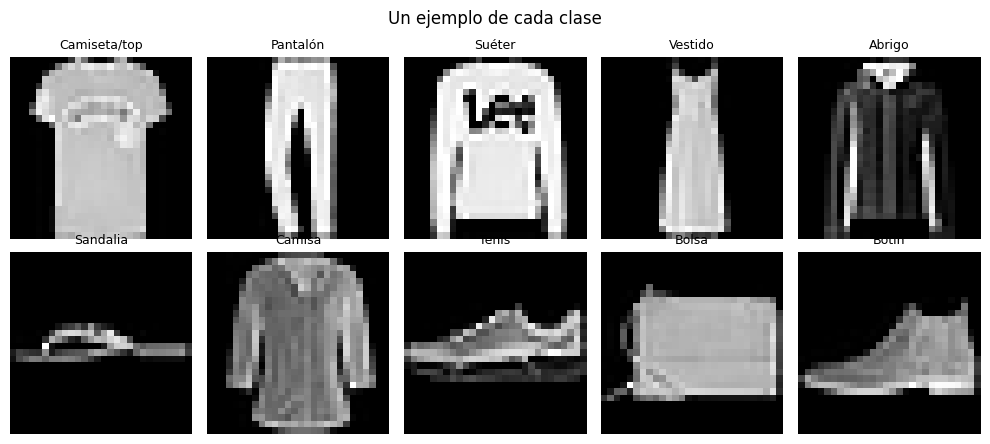

In [4]:
plt.figure(figsize=(10, 4.5))
for i in range(10):
    idx = np.where(y_test == i)[0][0]
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_test[idx], cmap='gray')
    plt.title(CLASES[i], fontsize=9); plt.axis('off')
plt.suptitle('Un ejemplo de cada clase'); plt.tight_layout(); plt.show()

## 4. ¿Qué hace `Flatten`?
`Flatten` convierte la imagen 2D de 28×28 en un vector 1D de **784** valores, que es la entrada que necesita una capa `Dense`.

Antes de Flatten: (1, 28, 28, 1) → Después de Flatten: (1, 784)


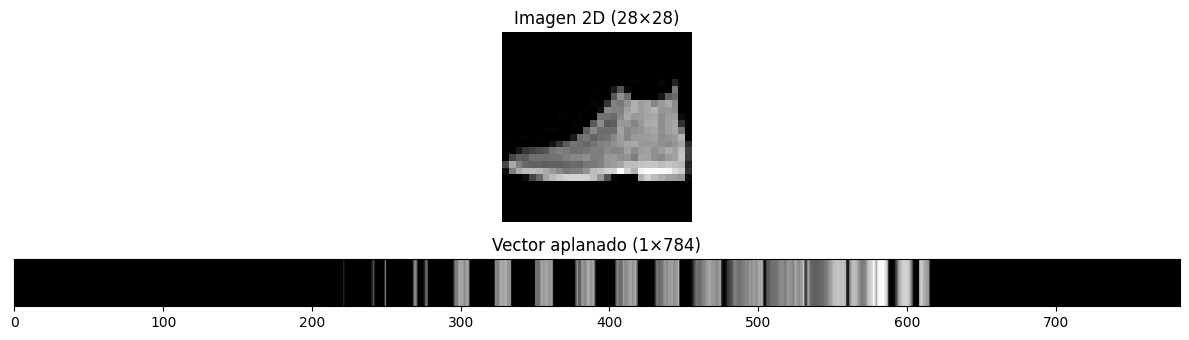

In [5]:
ejemplo = x_test[:1][..., None]
plano = keras.layers.Flatten()(ejemplo)
print('Antes de Flatten:', ejemplo.shape, '→ Después de Flatten:', plano.shape)

fig, axes = plt.subplots(2, 1, figsize=(12, 3.5), gridspec_kw={'height_ratios': [4, 1]})
axes[0].imshow(x_test[0], cmap='gray'); axes[0].set_title('Imagen 2D (28×28)'); axes[0].axis('off')
axes[1].imshow(plano.numpy(), aspect='auto', cmap='gray'); axes[1].set_title('Vector aplanado (1×784)'); axes[1].set_yticks([])
plt.tight_layout(); plt.show()

## 5. Tres configuraciones de red
| Config | Arquitectura | Idea |
|---|---|---|
| **A** | Flatten → Dense(10, softmax) | Línea base: clasificador lineal (regresión logística) |
| **B** | Flatten → Dense(128, ReLU) → Dense(10) | Una capa oculta |
| **C** | Flatten → Dense(256, ReLU) → Dropout(0.3) → Dense(128, ReLU) → Dropout(0.3) → Dense(10) | Más profunda y con regularización |

Todas usan `Adam`, `sparse_categorical_crossentropy` y se entrenan **10 épocas** con la misma semilla.

In [6]:
def config_A():
    return keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Flatten(),
        keras.layers.Dense(10, activation='softmax'),
    ], name='A_lineal')

def config_B():
    return keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Flatten(),
        keras.layers.Dense(128, activation='relu'),
        keras.layers.Dense(10, activation='softmax'),
    ], name='B_1_oculta')

def config_C():
    return keras.Sequential([
        keras.layers.Input(shape=(28, 28, 1)),
        keras.layers.Flatten(),
        keras.layers.Dense(256, activation='relu'),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(128, activation='relu', name='oculta_final'),
        keras.layers.Dropout(0.3),
        keras.layers.Dense(10, activation='softmax'),
    ], name='C_profunda_dropout')

EPOCAS = 10
resultados, historias, modelos = {}, {}, {}
for crear in [config_A, config_B, config_C]:
    tf.random.set_seed(SEED)
    m = crear()
    m.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    h = m.fit(train_n, validation_data=test_n, epochs=EPOCAS, verbose=0)
    _, acc = m.evaluate(test_n, verbose=0)
    resultados[m.name], historias[m.name], modelos[m.name] = acc, h.history, m
    print(f'{m.name:20s} parámetros={m.count_params():>8,}  accuracy prueba={acc:.4f}')

A_lineal             parámetros=   7,850  accuracy prueba=0.8407


B_1_oculta           parámetros= 101,770  accuracy prueba=0.8784


C_profunda_dropout   parámetros= 235,146  accuracy prueba=0.8700


## 6. Comparación de accuracy

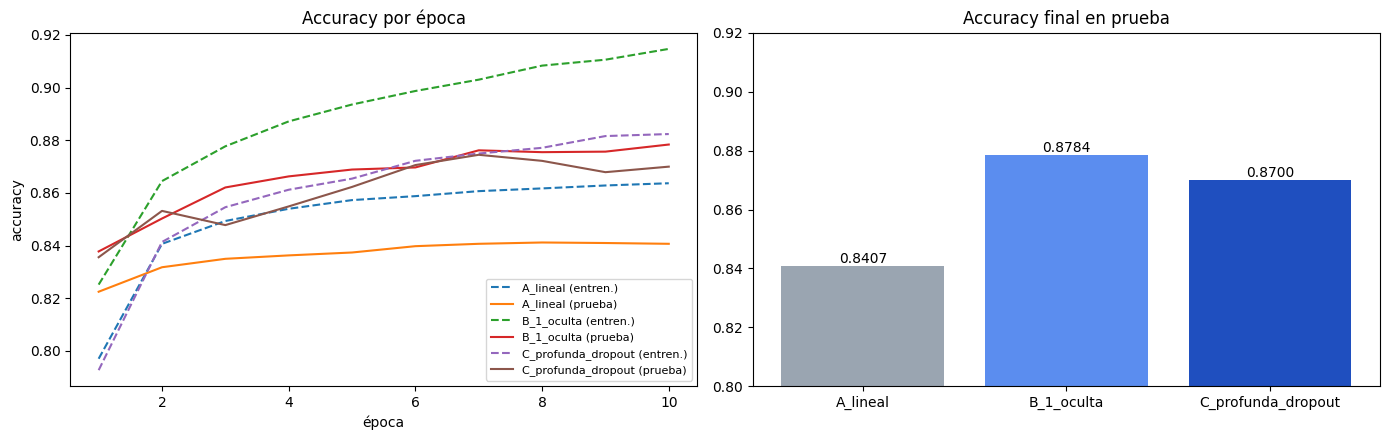

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, h in historias.items():
    axes[0].plot(range(1, EPOCAS + 1), h['accuracy'], '--', label=f'{nombre} (entren.)')
    axes[0].plot(range(1, EPOCAS + 1), h['val_accuracy'], '-', label=f'{nombre} (prueba)')
axes[0].set_title('Accuracy por época'); axes[0].set_xlabel('época'); axes[0].set_ylabel('accuracy')
axes[0].legend(fontsize=8)

nombres = list(resultados)
barras = axes[1].bar(nombres, [resultados[n] for n in nombres], color=['#9aa5b1', '#5b8def', '#1f4fbf'])
axes[1].bar_label(barras, fmt='%.4f')
axes[1].set_ylim(0.8, 0.92); axes[1].set_title('Accuracy final en prueba')
plt.tight_layout(); plt.show()

## 7. Matriz de confusión del mejor modelo

Mejor configuración: B_1_oculta (accuracy = 0.8784)


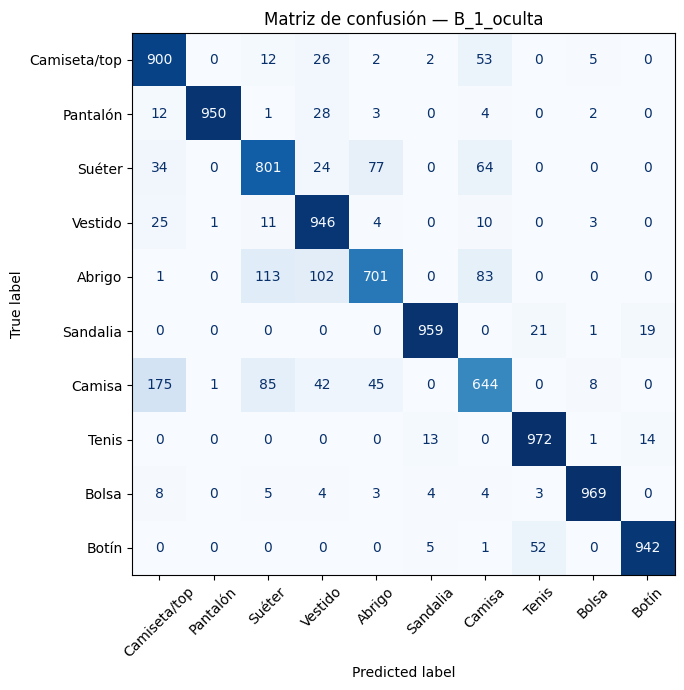

In [8]:
mejor = max(resultados, key=resultados.get)
modelo = modelos[mejor]
pred = modelo.predict(x_test[..., None], verbose=0).argmax(axis=1)
print('Mejor configuración:', mejor, f'(accuracy = {resultados[mejor]:.4f})')
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=CLASES).plot(
    ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
ax.set_title(f'Matriz de confusión — {mejor}'); plt.tight_layout(); plt.show()

## 8. Gráfica 2D de lo que aprendió la red
Se toman las activaciones de la última capa oculta y se proyectan a **2 dimensiones con PCA**. Si la red aprendió bien, las prendas de la misma clase quedan agrupadas.

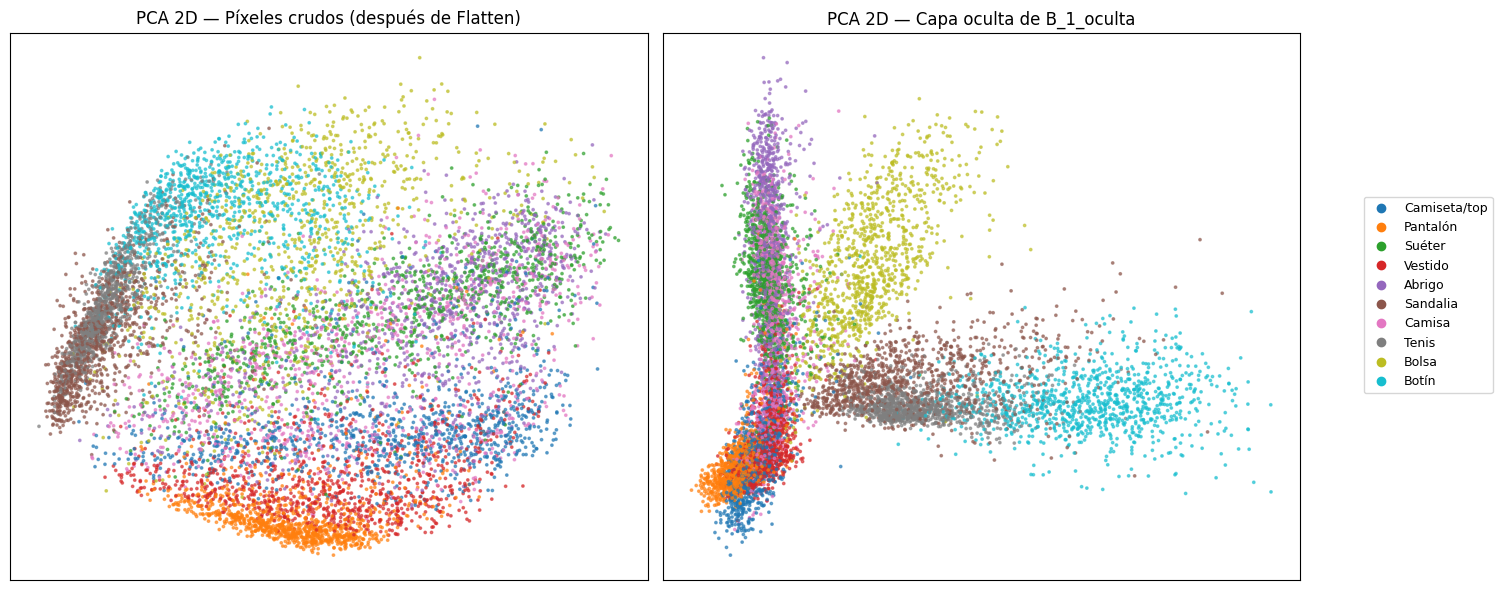

In [9]:
extractor = keras.Model(modelo.inputs, modelo.layers[-2].output if mejor != 'C_profunda_dropout'
                        else modelo.get_layer('oculta_final').output)
emb = extractor.predict(x_test[..., None], verbose=0)
emb2d = PCA(n_components=2, random_state=SEED).fit_transform(emb)
pix2d = PCA(n_components=2, random_state=SEED).fit_transform(x_test.reshape(len(x_test), -1))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, datos, titulo in [(axes[0], pix2d, 'Píxeles crudos (después de Flatten)'),
                          (axes[1], emb2d, f'Capa oculta de {mejor}')]:
    sc = ax.scatter(datos[:, 0], datos[:, 1], c=y_test, cmap='tab10', s=3, alpha=0.6)
    ax.set_title(f'PCA 2D — {titulo}'); ax.set_xticks([]); ax.set_yticks([])
handles = [plt.Line2D([], [], marker='o', ls='', color=plt.cm.tab10(i / 9), label=c) for i, c in enumerate(CLASES)]
fig.legend(handles=handles, loc='center right', fontsize=9)
plt.tight_layout(rect=[0, 0, 0.88, 1]); plt.show()

## 9. Algunas predicciones

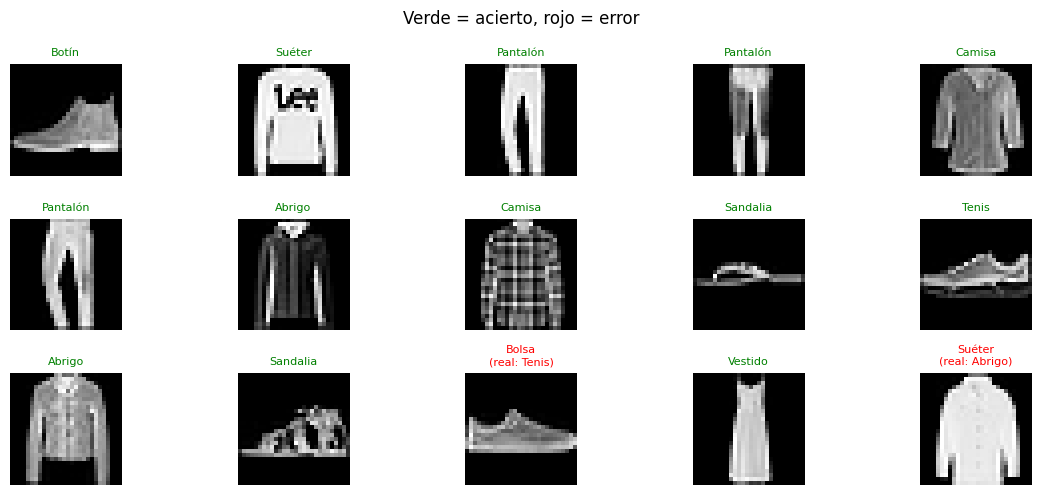

In [10]:
plt.figure(figsize=(12, 5))
for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i], cmap='gray'); plt.axis('off')
    ok = pred[i] == y_test[i]
    plt.title(f'{CLASES[pred[i]]}' + ('' if ok else f'\n(real: {CLASES[y_test[i]]})'),
              color='green' if ok else 'red', fontsize=8)
plt.suptitle('Verde = acierto, rojo = error'); plt.tight_layout(); plt.show()

## 10. Conclusiones
- **Config A (lineal, ~84 %)**: aun sin capas ocultas, `Flatten` + una capa `Dense` clasifica bien la mayoría de las prendas, pero se estanca porque solo puede trazar fronteras lineales.
- **Config B (una capa oculta de 128, ~88 %)**: fue la mejor. Agregar una capa oculta con ReLU le permite aprender combinaciones no lineales de los píxeles y sube casi 4 puntos de accuracy. Sin embargo, su accuracy de entrenamiento (~91 %) ya supera a la de prueba, señal de un ligero sobreajuste.
- **Config C (dos capas + Dropout, ~87 %)**: tiene más del doble de parámetros, pero en 10 épocas no superó a B. El *dropout* reduce el sobreajuste (sus curvas de entrenamiento y prueba están más juntas), aunque hace que aprenda más lento; con más épocas probablemente alcanzaría o superaría a B.
- La **matriz de confusión** muestra que los errores se concentran en prendas parecidas: *camisa*, *camiseta*, *suéter* y *abrigo*.
- La **gráfica PCA 2D** lo confirma: con los píxeles crudos las clases están muy mezcladas, mientras que en la capa oculta la red separa claramente calzado, bolsas y ropa, y las prendas de la parte superior del cuerpo quedan juntas.
- Para mejorar aún más se podría usar una **red convolucional (CNN)**, que aprovecha la estructura 2D de la imagen en lugar de aplanarla desde el inicio.